# 22 · MCP: build a server, connect a client, use its tools in a LangGraph graph
Level L4 · Part 4 · core · ~25 min · builds on 07

## Goal
Expose the order tools as an MCP server, call them over the protocol, and then give them to a LangGraph agent, so the
agent can look up an order it was never wired to. The server runs as its own process; the graph talks to it through an
MCP client.

## Why it matters
Lesson 06 gave the model one tool, wired into one script. A second app that needs `lookup_order` (the support chat, the
returns page, the phone bot) would copy the function, and the copies would drift. Without a protocol, every app writes its
own tool contract, and every change goes out in every app.

| Without MCP | With MCP |
|---|---|
| Each app copies the tool, its schema and its error text | One server publishes the tools, with their schemas, once |
| A change to a tool means a change in every app | The server changes; every client sees the new schema on its next connection |
| A client has to know how the tool runs | The client asks the server what it offers, then calls it by name |

**What it makes easy:** one tool server for many agents. **When you don't need it:** one script with one tool; lesson 06
is enough.

## The idea
MCP is a request-and-reply protocol between a **client** (the agent's side) and a **server** (the tools' side). The client
starts the conversation with `initialize`, then asks what the server offers. The server answers with tools (functions the
model may call), resources (data read by a URI) and prompts (templates). The client calls a tool by name, with arguments
that match the schema the server published. The transport is how the messages travel: here, **stdio**, a pipe between the
client and a server process it starts itself.

Analogy: a catalogue at a shop counter. The counter (the client) asks for the list of services; the back office (the
server) publishes it, and fulfils each request by name.

## Picture
The client and the server are two processes. The graph never sees the wire: it sees one tool per MCP tool.

Two course helpers from `graph_view.py` draw flowcharts. `show_mermaid` draws Mermaid text, as below; `show_graph` draws a
compiled LangGraph graph (used in Step 5). Both need the internet for the picture, and offline they print the text instead.

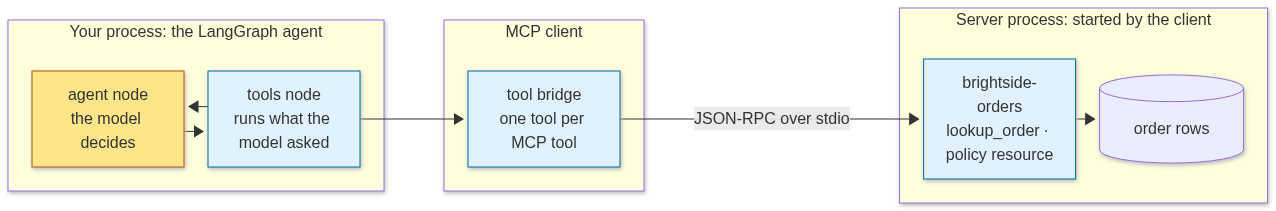

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: graph_view.py and llm_setup.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  subgraph AGENT["Your process: the LangGraph agent"]
    A["agent node<br/>the model decides"] --> T["tools node<br/>runs what the model asked"]
    T --> A
  end
  subgraph MCP["MCP client"]
    C["tool bridge<br/>one tool per MCP tool"]
  end
  subgraph SRV["Server process: started by the client"]
    S["brightside-orders<br/>lookup_order · policy resource"] --> D[("order rows")]
  end
  T --> C
  C -- "JSON-RPC over stdio" --> S
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class A model
  class T,C,S code
""")

## Step by step
**Step 1 · setup.** The imports and the paths. `Client` talks to a server, and `StdioServerParameters` says how to start
one. This cell makes no model call.

In [2]:
from pathlib import Path

from langchain_core.tools import StructuredTool  # a LangChain tool: name, description, schema, function
from mcp import Client, StdioServerParameters

Path("../../../data/lg22").mkdir(parents=True, exist_ok=True)  # the folder for this lesson's run-time files
SERVER = Path("../../../data/lg22/orders_server.py").resolve()  # written in Step 2
STDIO = StdioServerParameters(command=sys.executable, args=[str(SERVER)])  # how the client starts the server
print("the server file this lesson writes:", SERVER.name)

the server file this lesson writes: orders_server.py


**Step 1 · the model.** `get_llm()` is the course's shared model setup: it reads its key from `.env`, never typed here.
`llm_replay` is the course helper that saves the model's answers the first time and replays them later, so later runs
need no key. The lesson makes two model calls, both in Step 5.

In [3]:
import llm_replay  # the course helper: records and replays model calls (not part of MCP or LangGraph)
llm_replay.start("22_mcp-server-and-client")

from langchain_core.messages import HumanMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from llm_setup import get_llm  # the course's shared model setup (Gemini on Vertex AI, temperature 0)

from graph_view import show_graph  # draws the compiled graph in Step 5

llm = get_llm()

LLM mode: replay (22_mcp-server-and-client.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 2 · write the server.** The server is a file that the client starts. Two decorators declare a tool and a resource:
the decorator reads the function's name, its arguments and its docstring, and turns them into the schema the client
receives. Nothing in the client is written by hand. The data is the same fictional orders as the earlier lessons.

In [4]:
%%writefile ../../../data/lg22/orders_server.py
"""The Brightside order tools as an MCP server (lesson 22). The client starts this file over stdio."""
import json
from pathlib import Path

from mcp.server import MCPServer

GOLDEN = json.loads((Path(__file__).resolve().parents[1] / "support_eval.json").read_text())
ORDERS = GOLDEN["world"]["orders"]  # fictional rows, the same ones as the earlier lessons
POLICY = GOLDEN["policy"]

mcp = MCPServer("brightside-orders", instructions="Read-only order tools for the Brightside Outfitters support desk.",
                log_level="WARNING")


@mcp.tool()
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status, days late and total. Use it when the customer gives an order number."""
    if order_id not in ORDERS:  # the error names the next step, as in lesson 07
        return {"error": f"no order {order_id}", "next_step": "Ask for the number in the confirmation email."}
    return ORDERS[order_id]


@mcp.resource("policy://returns")
def returns_policy() -> str:
    """The refund and return policy the support desk follows."""
    return POLICY


if __name__ == "__main__":
    mcp.run()  # stdio: the client starts this file and talks over stdin and stdout

Overwriting ../../../data/lg22/orders_server.py


**Step 3 · the wire, one request at a time (no model call).** `Client(STDIO)` starts the server and performs `initialize`.
Then `list_tools` asks what the server offers, `call_tool` runs a tool, and `read_resource` reads the policy by its URI.
The server runs in a separate process, so a `print()` in the server would corrupt the stream the client reads; log to
stderr instead.

In [5]:
async def wire_demo():
    async with Client(STDIO) as client:  # starts the server process and sends initialize
        listed = (await client.list_tools()).tools
        for tool in listed:
            print(tool.name, "| needs:", tool.input_schema["required"], "|", tool.description)
        result = await client.call_tool("lookup_order", {"order_id": "1002"})
        print("call_tool ->", result.content[0].text)
        policy = await client.read_resource("policy://returns")
        print("read_resource ->", policy.contents[0].text[:60] + "…")
    return listed


listed_tools = await wire_demo()

lookup_order | needs: ['order_id'] | Look up one customer order: its status, days late and total. Use it when the customer gives an order number.
call_tool -> {
  "status": "in transit",
  "days_late": 4,
  "total": 45.0
}
read_resource -> Refund only when the order is lost, or delivered and the cus…


Read the output: the schema came from the server's function. `order_id` is required, and the description is the docstring.
`call_tool` returned order 1002 as JSON, and `read_resource` returned the start of the returns policy.

**Step 4 · bridge the server's tools into LangChain.** A LangGraph agent wants tools as LangChain objects. The bridge makes
one `StructuredTool` per MCP tool. Its schema is the server's `input_schema`, and its coroutine sends the call over the open
client. It is about ten lines: the LangChain adapter package for MCP (`langchain-mcp-adapters`) is archived and caps `mcp`
below version 2, the version this course uses, so the course writes the bridge itself. The last lines of the cell build
the tools without a client, to show that nothing reaches the server until a tool runs.

In [6]:
def bridge(client, listed):
    """One LangChain tool per MCP tool. The tool runs on the server; the bridge only passes the call along."""
    async def call(name: str, **args) -> str:
        result = await client.call_tool(name, args)
        return result.content[0].text

    return [StructuredTool(name=t.name, description=t.description, args_schema=t.input_schema,
                           coroutine=lambda _n=t.name, **a: call(_n, **a)) for t in listed]


# The check: building the tools makes no call, so it passes None for the client; a call happens only when a tool runs.
for t in bridge(None, listed_tools):
    print(t.name, "| args:", list(t.args))

lookup_order | args: ['order_id']


**Step 5 · the agent as a graph, with the server's tools (2 model calls).** The model sees the bridged tools and asks for
`lookup_order`. The `tools` node runs the call over MCP and returns the result. The model then writes the answer. The
session opens for the whole run and closes after it, so the server process lives exactly as long as the agent needs it.

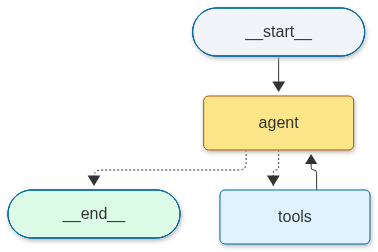

the model asks the server for: lookup_order {'order_id': '1003'}
the server returns: {
  "status": "lost",
  "days_late": 9,
  "total": 89.5
}
answer: Order 1003 is currently marked as "lost" and is 9 days late.


In [7]:
async def run_agent(question: str) -> None:
    async with Client(STDIO) as client:
        tools = bridge(client, (await client.list_tools()).tools)
        model = llm.bind_tools(tools)

        def agent(state: MessagesState) -> dict:
            return {"messages": [model.invoke(state["messages"])]}  # the model: a tool request, or the answer

        g = StateGraph(MessagesState)
        g.add_node("agent", agent)
        g.add_node("tools", ToolNode(tools))  # runs each tool the model asked for
        g.add_edge(START, "agent")
        g.add_conditional_edges("agent", tools_condition, {"tools": "tools", END: END})
        g.add_edge("tools", "agent")
        app = g.compile()
        show_graph(app, model_nodes=("agent",))
        final = await app.ainvoke({"messages": [HumanMessage(content=question)]})
        for m in final["messages"][1:]:
            for call in getattr(m, "tool_calls", []) or []:
                print("the model asks the server for:", call["name"], call["args"])
            if m.type == "tool":
                print("the server returns:", m.content)
        print("answer:", final["messages"][-1].text)


await run_agent("Order 1003 never arrived. Look up order 1003: what is its status, and how late is it?")
llm_replay.stop()  # the last model call of this lesson

## At work
- Teams run one tool server per system and let every agent connect to it, instead of copying the tools into each app.
  The model sees the schema the server publishes, so a fix to a description reaches every client → lesson 23 (discovery).
- A tool server is code that runs with the agent's permissions. Teams allow-list which servers an agent may use and read
  each server's tools before they connect → lesson 24 (registry, gateway and auth).
- The transport changes between laptop and production: stdio for a local process, Streamable HTTP for a remote server.
  The tool code stays the same → lesson 37 (serving).

## What just happened
- The model asked for `lookup_order` with `order_id` '1003'; the call went to the server process over MCP.
- The server returned status "lost", `days_late` 9 and `total` 89.5, read from its order table.
- The answer, "lost" and 9 days late, repeats those values; the graph kept no order data of its own.

## Common mistakes
1. **Calling a tool after the session has closed.** The tools call the server through the client, so the client must still
   be open when a tool runs. Open it around the whole graph run, as Step 5 does. The cell below uses the client after its
   block has ended, so it raises, with no model call.

In [8]:
async def after_close():
    async with Client(STDIO) as client:
        pass  # the session closes here
    return await client.call_tool("lookup_order", {"order_id": "1002"})  # the session is closed: this raises


try:
    await after_close()
except RuntimeError as error:  # print the message only: a full traceback shows file paths on this machine
    print("RuntimeError:", error)

RuntimeError: Client must be used within an async context manager


2. **A `print()` in the server.** Over stdio, stdout carries the protocol: each line the client reads must be one JSON
   message. The cell below runs a server that prints one line, then parses that line the way the client does. The parse
   fails, and the client logs such an error and skips the line. Log to stderr instead.

In [9]:
import json
import subprocess

stray = subprocess.run([sys.executable, "-c", 'print("starting the server")'], capture_output=True, text=True).stdout
try:
    json.loads(stray.splitlines()[0])
except json.JSONDecodeError as error:  # the message only, as above
    print(f"{type(error).__name__}: {str(error).splitlines()[0]}")

JSONDecodeError: Expecting value: line 1 column 1 (char 0)


3. **Trusting the description.** The model chooses tools from the descriptions the server publishes. A description written
   by someone else can steer the model. Read the descriptions of every server you connect → lesson 24.

## Try it
Write `required_args(tools)`. It takes the tool list from `list_tools()` and returns a dict that maps each tool's name to
the arguments the schema requires. No model call is needed. Use the `listed_tools` from Step 3.

In [10]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [11]:
def required_args(tools) -> dict:
    return {t.name: list(t.input_schema.get("required", [])) for t in tools}


print(required_args(listed_tools))  # {'lookup_order': ['order_id']}

{'lookup_order': ['order_id']}


## Key terms
- **MCP (Model Context Protocol)** — the protocol by which a client lists and calls a server's tools, resources and prompts.
- **Client** — the side that asks: here, the agent's MCP client, which starts the server and sends requests.
- **Server** — the side that publishes tools and resources; here, `brightside-orders`.
- **Tool** — a function the server publishes with a name and a schema; the model may ask for it to be called.
- **Resource** — data the server publishes under a URI, such as `policy://returns`; the client reads it.
- **Transport** — how messages travel; **stdio** is a pipe to a process the client starts.
- **Bridge** — the code that wraps each MCP tool as a LangChain tool so the graph can call it.

## Recap
- MCP is a protocol between a client and a server. The client lists the server's tools and calls them by name.
- The server publishes each tool's schema from its own function, so the client writes nothing per tool.
- A bridge turns each MCP tool into a LangChain tool, and the graph calls them like any other tool.
- The server is a separate process. Keep the session open for the run, and keep stdout clean.

**Interview:** "How does an agent use a tool that lives in another service?" Strong answer: "The service publishes the tool
through MCP, with a schema. My client lists the tools at connection, wraps each one as a tool for the model, and calls it
over the protocol. The schema and the implementation stay in the server, so one change reaches every agent."